# 01 · Ingest: turn a 10-K PDF into searchable chunks

**You'll learn:** how the filing becomes a searchable database: downloading it, cutting it into passages two different ways, turning passages into vectors, and storing them in Qdrant.

**Time:** about 10 minutes (longer the first time docling runs) · **Cost:** under 1¢, plus about a cent if it has to embed everything · **Needs:** an API key in `.env`, and a database: Docker Qdrant running, or `USE_EMBEDDED_QDRANT = True`.

```mermaid
flowchart LR
  PDF["10-K PDF<br/>121 pages"] --> B["Basic chunker<br/>PyPDF text + regex Items<br/>800-token pieces"]
  PDF --> A["Advanced chunker<br/>docling layout<br/>tables kept whole"]
  B --> EB["Embed<br/>dense + sparse"] --> QB[("sec_filings_basic")]
  A --> EA["Embed<br/>dense + sparse"] --> QA[("sec_filings_advanced<br/>used by Q&A")]
```

| Part | What it covers | Code |
|---|---|---|
| 1 | Setup | |
| 2 | Fetch the filing | `ingestion/fetch_filing_pdf.py` |
| 3 | Chunk it two ways, and compare | `ingestion/chunk_filings_basic.py`, `ingestion/chunk_filings_advanced.py` |
| 4 | Embed: dense and sparse vectors | `core/embeddings.py`, `core/clients.py` |
| 5 | Index into Qdrant | `ingestion/index_to_qdrant.py`, `ingestion/index_comparison_collections.py` |
| 6 | Recap and things to try | |

New to tokens, embeddings or BM25? Run `00_start_here.ipynb` first.

---
## Part 1 · Setup

### Setup
The next cell connects the notebook to the project. Read its first lines: `USE_EMBEDDED_QDRANT` picks where the database runs (Docker server, or embedded with no Docker). It prints which LLM, embedding model and database this run uses, all taken from your `.env`.

In [1]:
# ── Settings ────────────────────────────────────────────────────────────
# False: use the Qdrant server from `docker compose up -d`.
# True:  no Docker. Qdrant runs inside this notebook and stores data in data/qdrant_local/.
#        Restart the kernel after changing this, and run one notebook at a time
#        (only one process can open the embedded folder).
USE_EMBEDDED_QDRANT = False

# Setup: run from the repo root so `core`/`ingestion` imports and data/ paths work.
import logging
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
logging.basicConfig(level=logging.WARNING)
if USE_EMBEDDED_QDRANT:
    os.environ["QDRANT_PATH"] = "data/qdrant_local"
warnings.filterwarnings("ignore", message="Qdrant client version")  # harmless client/server version notice

import pandas as pd

import core  # noqa: F401  (loads .env)
import core.embeddings as emb
import core.llm as llm
from core.clients import COLLECTION_NAME, QDRANT_PATH, QDRANT_URL, get_qdrant_client

pd.set_option("display.max_colwidth", 120)
print(f"LLM:        {llm.PROVIDER} / {llm.MODEL}")
print(f"Embeddings: {emb.PROVIDER} / {emb.MODEL}")
print(f"Qdrant:     {'embedded @ ' + QDRANT_PATH if QDRANT_PATH else 'server @ ' + QDRANT_URL}")

LLM:        gemini / gemini-3.5-flash
Embeddings: gemini / gemini-embedding-001
Qdrant:     server @ http://localhost:6333


---
## Part 2 · Fetch the filing

A 10-K is organised into numbered **Items**. These are the ones you'll see most in answers:

| Item | Contents |
|---|---|
| Item 1 | Business: products, segments, competition |
| Item 1A | Risk Factors |
| Item 1C | Cybersecurity |
| Item 7 | Management's Discussion and Analysis (MD&A): why the numbers moved |
| Item 8 | Financial Statements: income statement, balance sheet, notes |

`fetch_filing_pdf()` downloads Apple's own published PDF once to `data/raw_pdf/AAPL.pdf`; later runs reuse the file.

In [2]:
from pypdf import PdfReader

from ingestion.fetch_filing_pdf import fetch_filing_pdf

pdf_path = fetch_filing_pdf("AAPL")
reader = PdfReader(pdf_path)
print(f"{pdf_path}: {pdf_path.stat().st_size / 1e6:.1f} MB, {len(reader.pages)} pages\n")
print("Start of page 1:\n", reader.pages[0].extract_text()[:500])

data/raw_pdf/AAPL.pdf: 1.1 MB, 121 pages

Start of page 1:
 UNITED STATES
SECURITIES AND EXCHANGE COMMISSION
Washington, D.C. 20549
FORM 10-K
(Mark One)
☒ ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934
For the fiscal year ended September 28, 2024
or
☐ TRANSITION REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934
For the transition period from              to             .
Commission File Number: 001-36743
Apple Inc.
(Exact name of Registrant as specified in its charter)
California 94-240411


---
## Part 3 · Chunk it two ways

### 3.1 Why chunk at all?

We can't search or prompt with the whole 121-page PDF at once. We cut it into **chunks**: passages small enough that:
- a search can point at the *specific* passage that answers a question, not a whole chapter;
- 8 of them fit comfortably in one LLM prompt;
- each one still has enough surrounding context to make sense alone.

How you cut matters a lot, especially for financial tables. The project tries two ways so you can compare them.

### 3.2 Basic chunker

1. Extract plain text page by page with PyPDF.
2. Find the "Item 1A", "Item 7"… headers with a regular expression, so each chunk knows its section.
3. Split each section into pieces of up to **800 tokens**, with **150 tokens of overlap** between neighbouring pieces, so a sentence cut at a boundary still appears whole in one of them.

It's fast, but PDF text extraction flattens tables into lines of loose numbers.

In [3]:
import json
from collections import Counter

from core.models import FilingChunk
from ingestion.chunk_filings_basic import chunk_filing_basic


def save_chunks(chunks, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps([c.__dict__ for c in chunks], indent=2), encoding="utf-8")


basic_chunks = chunk_filing_basic("AAPL", pdf_path, fiscal_year="2024")
save_chunks(basic_chunks, Path("data/chunks_basic/AAPL.json"))

print(f"basic: {len(basic_chunks)} chunks across {len({c.section for c in basic_chunks})} sections\n")
for section, count in Counter(c.section[:60] for c in basic_chunks).most_common(6):
    print(f"{count:4} chunks  {section}")

basic: 168 chunks across 44 sections

  68 chunks  Item 16.    Form 10-K Summary
  24 chunks  Item 8.    Financial Statements and Supplementary Data
  19 chunks  Item 1A.    Risk Factors
   6 chunks  Item 7.    Management’s Discussion and Analysis of Financial
   6 chunks  Item 15.    Exhibit and Financial Statement Schedules
   5 chunks  Item 1.    Business


### 3.3 Advanced chunker

**docling** reads the PDF's *layout*, not just its text: it recognises headings, paragraphs and tables. Its `HybridChunker` then:
- keeps each table together and writes it as a **markdown table**, so rows and columns survive;
- merges small neighbouring pieces and splits big ones, so each chunk is **at most 800 tokens** (counted with the gpt-4o tokenizer);
- records the heading path, e.g. `Item 8 > Note 13 - Segment Information`.

The first run is slow because docling downloads its layout models, so the result is reused from `data/chunks_advanced/` when it exists. Set `RECHUNK = True` to rebuild it (several minutes).

In [4]:
from ingestion.chunk_filings_advanced import chunk_filing_advanced

RECHUNK = False  # True = run docling again

adv_path = Path("data/chunks_advanced/AAPL.json")
if RECHUNK or not adv_path.exists():
    advanced_chunks = chunk_filing_advanced("AAPL", pdf_path, fiscal_year="2024")
    save_chunks(advanced_chunks, adv_path)
else:
    advanced_chunks = [FilingChunk(**c) for c in json.loads(adv_path.read_text(encoding="utf-8"))]

print(f"advanced: {len(advanced_chunks)} chunks")
print(f"chunks containing a markdown table: {sum('|' in c.text for c in advanced_chunks)}")

advanced: 310 chunks
chunks containing a markdown table: 49


### 3.4 What one chunk looks like

Every chunk is a `FilingChunk` (`core/models.py`). Its fields become the **payload** stored next to the vectors in Qdrant, which is how an answer can cite "Apple Inc. · Item 7 · FY2024".

In [5]:
example = advanced_chunks[len(advanced_chunks) // 2]
pd.Series({k: (v[:200] + "…" if isinstance(v, str) and len(v) > 200 else v) for k, v in example.__dict__.items()})

ticker                                                                                                                             AAPL
company_name                                                                                                                 Apple Inc.
filing_type                                                                                                                        10-K
section                                                       Item 8.    Financial Statements and Supplementary Data > Commercial Paper
fiscal_year                                                                                                                        2024
text            Commercial Paper\nThe Company issues unsecured short-term promissory notes pursuant to a commercial paper program. T...
pipeline                                                                                                                       advanced
dtype: str

### 3.5 How big are the chunks?

The dashed line is the 800-token cap. Basic chunks pile up just under it, because the splitter fills each piece. Advanced chunks vary more: a short paragraph stays short. A few advanced chunks land slightly above 800 because docling adds the heading path after sizing the chunk.

,count,mean,std,min,25%,50%,75%,max
pipeline,,,,,,,,
advanced,310.0,304.0,255.0,6.0,85.0,222.0,528.0,807.0
basic,168.0,602.0,293.0,7.0,680.0,756.0,774.0,795.0


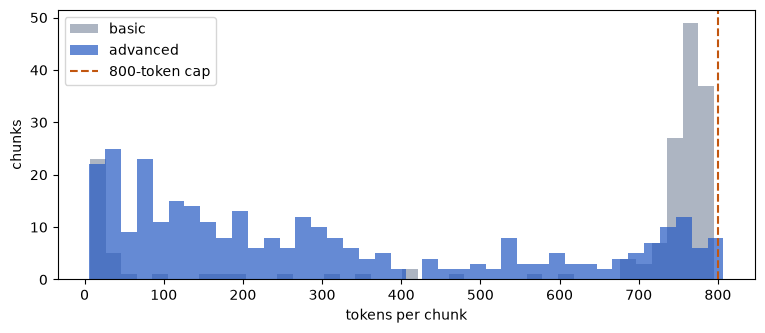

In [6]:
import matplotlib.pyplot as plt
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o")
sizes = pd.DataFrame({
    "pipeline": ["basic"] * len(basic_chunks) + ["advanced"] * len(advanced_chunks),
    "tokens": [len(enc.encode(c.text)) for c in basic_chunks + advanced_chunks],
})
display(sizes.groupby("pipeline")["tokens"].describe().round(0))

fig, ax = plt.subplots(figsize=(9, 3.5))
for name, color in [("basic", "#8A96A8"), ("advanced", "#2459C2")]:
    ax.hist(sizes[sizes.pipeline == name].tokens, bins=40, alpha=0.7, label=name, color=color)
ax.axvline(800, color="#C2560F", linestyle="--", label="800-token cap")
ax.set_xlabel("tokens per chunk")
ax.set_ylabel("chunks")
ax.legend()
plt.show()

### 3.6 Same table, two chunkers

The clearest difference is on tables. Below is the geographic net-sales table as each chunker stored it. In the basic version the numbers run together on lines; in the advanced version each row and column is still there, which helps both the search and the LLM.

In [7]:
def first_with(chunks, needle):
    return next((c for c in chunks if needle in c.text), None)


for name, chunks in [("BASIC", basic_chunks), ("ADVANCED", advanced_chunks)]:
    chunk = first_with(chunks, "Total net sales")
    print(f"===== {name} · section: {chunk.section[:70]}")
    start = max(chunk.text.find("Total net sales") - 300, 0)
    print(chunk.text[start:start + 700], "\n")

===== BASIC · section: Item 7.    Management’s Discussion and Analysis of Financial Condition
t for 2024, 2023 and 2022 (dollars in millions):
2024 Change 2023 Change 2022
Americas $ 167,045 3 % $ 162,560 (4)% $ 169,658 
Europe 101,328 7 % 94,294 (1)% 95,118 
Greater China 66,952 (8)% 72,559 (2)% 74,200 
Japan 25,052 3 % 24,257 (7)% 25,977 
Rest of Asia Pacific 30,658 4 % 29,615 1 % 29,375 
Total net sales $ 391,035 2 % $ 383,285 (3)% $ 394,328 
Americas
Americas net sales increased during 2024 compared to 2023 due primarily to higher net sales of Services.
Europe
Europe net sales increased during 2024 compared to 2023 due primarily to higher net sales of Services and iPhone.
Greater China
Greater China net sales decreased during 2024 compared to 2023 due primarily to lower net sales 

===== ADVANCED · section: Item 7.    Management's Discussion and Analysis of Financial Condition
 | - | - |
| Americas | $ 167,045 | 3 % | $ 162,560 | (4)% | $ 169,658 |
| Europe | 101,328 | 7 % | 94,294

> **Pitfall:** chunks are tagged `fiscal_year="2024"` by a default in the chunkers, whichever year the PDF actually covers. If Apple publishes a newer 10-K, the label won't change by itself.

---
## Part 4 · Embed: dense and sparse vectors

Each chunk gets **two** vectors:

| | Dense | Sparse (BM25) |
|---|---|---|
| What it captures | meaning | exact words |
| Shape | 1536 numbers, all filled in | a weight for each distinct word in the chunk |
| Made by | OpenAI `text-embedding-3-small` or Gemini `gemini-embedding-001` (`EMBEDDING_PROVIDER`) | fastembed `Qdrant/bm25`, locally, free |
| Good at | paraphrases: "revenue" ≈ "net sales" | names, numbers, jargon: "Item 1C", "Greater China" |

Here we embed just 3 chunks to see the shapes (a fraction of a cent).

In [8]:
import tiktoken

from core.clients import get_sparse_model
from core.embeddings import embed_dense

enc = tiktoken.encoding_for_model("gpt-4o")  # rough token count, used only for the estimate

sample = [c.text for c in advanced_chunks[:3]]
dense = embed_dense(sample)
print(f"dense:  {len(dense)} vectors x {len(dense[0])} numbers, first five: {[round(x, 4) for x in dense[0][:5]]}")

sparse = next(get_sparse_model().embed([sample[0]]))
print(f"sparse: {len(sparse.indices)} non-zero entries (one per distinct word), e.g. {list(zip(sparse.indices[:3].tolist(), sparse.values[:3].round(3).tolist()))}")
print("        (each index is a hashed word id; each value is that word's BM25 weight)")

total_tokens = sum(len(enc.encode(c.text)) for c in basic_chunks + advanced_chunks)
print(f"\nEmbedding all {len(basic_chunks) + len(advanced_chunks)} chunks = about {total_tokens:,} tokens")

Embedding with Gemini:   0%|          | 0/3 [00:00<?, ?chunk/s]

dense:  3 vectors x 1536 numbers, first five: [-0.0125, 0.0058, 0.0027, -0.0797, -0.0094]
sparse: 8 non-zero entries (one per distinct word), e.g. [(1510964117, 1.656), (722829366, 1.656), (84077638, 1.656)]
        (each index is a hashed word id; each value is that word's BM25 weight)

Embedding all 478 chunks = about 195,470 tokens


---
## Part 5 · Index into Qdrant

Qdrant stores **points** inside **collections**:

```mermaid
flowchart LR
  subgraph COL["Collection: sec_filings_advanced"]
    P1["Point #42<br/>dense vector (1536)<br/>sparse vector<br/>payload: ticker, section, fiscal_year, text"]
    P2["Point #43 …"]
  end
```

- A **collection** is like a table. There is one per chunker: `sec_filings_basic` and `sec_filings_advanced`.
- A **point** is one chunk: an id, its two vectors (named `dense` and `sparse`), and its payload.

This cell embeds **every** chunk of both chunkers and stores them. It skips the work when both collections already exist. Set `REINDEX = True` after changing `EMBEDDING_PROVIDER` or `EMBEDDING_MODEL`: vectors from different models can't be mixed in one collection.

In [9]:
# Is the vector database running?
try:
    names = [c.name for c in get_qdrant_client().get_collections().collections]
    print("Qdrant is up. Collections:", names or "(none yet)")
except Exception as exc:
    raise SystemExit(
        "Qdrant is not reachable. Either open Docker Desktop and run `docker compose up -d`, "
        "or set USE_EMBEDDED_QDRANT = True in the first cell and restart the kernel."
    ) from exc

Qdrant is up. Collections: ['sec_filings_advanced', 'sec_filings_basic', 'sec_filings_basic_gemini']


In [10]:
from ingestion.index_comparison_collections import (
    ADVANCED_COLLECTION,
    BASIC_COLLECTION,
    index_comparison_collections,
)

REINDEX = False

client = get_qdrant_client()
collections = (BASIC_COLLECTION, ADVANCED_COLLECTION)
if REINDEX or not all(client.collection_exists(name) for name in collections):
    for name in collections:
        if client.collection_exists(name):
            client.delete_collection(name)
    index_comparison_collections()  # embeds every chunk: a minute or two on OpenAI, ~10 min on Gemini's free tier (progress bar below)

for name in collections:
    print(f"{name}: {client.count(name).count} points")

[1/2] Indexing sec_filings_basic_gemini


Embedding with Gemini:   0%|          | 0/168 [00:00<?, ?chunk/s]

[2/2] Indexing sec_filings_advanced_gemini


Embedding with Gemini:   0%|          | 0/310 [00:00<?, ?chunk/s]

Done.
sec_filings_basic_gemini: 168 points
sec_filings_advanced_gemini: 310 points


Peek inside: the collection's vector settings, and one stored point's payload.

In [11]:
info = client.get_collection(ADVANCED_COLLECTION)
print("dense vectors: ", info.config.params.vectors)
print("sparse vectors:", list(info.config.params.sparse_vectors))

point = client.scroll(ADVANCED_COLLECTION, limit=1, with_payload=True, with_vectors=False)[0][0]
print(f"\npoint id {point.id}, payload:")
pd.Series({k: (v[:150] + "…" if isinstance(v, str) and len(v) > 150 else v) for k, v in point.payload.items()})

dense vectors:  {'dense': VectorParams(size=1536, distance=<Distance.COSINE: 'Cosine'>, hnsw_config=None, quantization_config=None, on_disk=None, datatype=None, multivector_config=None)}
sparse vectors: ['sparse']

point id 0, payload:


ticker                                                                              AAPL
company_name                                                                  Apple Inc.
filing_type                                                                         10-K
section                                 UNITED STATES SECURITIES AND EXCHANGE COMMISSION
fiscal_year                                                                         2024
text            UNITED STATES SECURITIES AND EXCHANGE COMMISSION\nWashington, D.C. 20549
dtype: str

---
## Part 6 · Recap and things to try

**What happened**
1. The 10-K PDF was downloaded once and cached.
2. It was chunked two ways: basic (fast, flattens tables) and advanced (layout-aware, tables kept whole).
3. Each chunk got a dense vector (meaning) and a sparse vector (exact words).
4. Both chunk sets were stored as points in two Qdrant collections. The Q&A uses `sec_filings_advanced`.

One command does all of this outside the notebook: `python -m ingestion.prepare`.

**Try this**
- Search the chunks for a word: `[c.section for c in advanced_chunks if "Vision Pro" in c.text]`.
- Compare how many chunks each chunker gave the Risk Factors section (`Item 1A`).
- Find the biggest advanced chunk and read it: `max(advanced_chunks, key=lambda c: len(c.text))`.

**Next:** `02_answer.ipynb` follows one question through search, fusion, prompt and citations.